In [1]:
%pip install pandas numpy matplotlib seaborn scikit-learn pillow

Note: you may need to restart the kernel to use updated packages.


In [2]:
from pathlib import Path

ROOT = Path(r"E:\Projects\Deepfake detector")

patterns = [
    "*.pt", "*.pth", "*.ckpt",
    "*.json", "*.csv"
]

for folder in ["experiments", "data/metadata"]:
    base = ROOT / folder
    print(f"\n--- {folder} ---")

    if not base.exists():
        print("Folder missing")
        continue

    files = []
    for pattern in patterns:
        files.extend(base.rglob(pattern))

    for path in sorted(set(files)):
        print(path.relative_to(ROOT))


--- experiments ---
experiments\benchmark-visualizations\cifake_report_metrics.csv
experiments\fft-baseline\cifake-image-v2\cifake-fft-resnet18-best.pt
experiments\fft-baseline\cifake-image-v2\cifake-fft-resnet18-config.json
experiments\fft-baseline\cifake-image-v2\cifake-fft-resnet18-history.json
experiments\fft-baseline\cifake-image-v2\cifake-fft-resnet18-report.json
experiments\fft-baseline\cifake-image-v2\comparison-report.json
experiments\fusion-baseline\cifake-image-v2\cifake-fusion-resnet18-best.pt
experiments\fusion-baseline\cifake-image-v2\cifake-fusion-resnet18-config.json
experiments\fusion-baseline\cifake-image-v2\cifake-fusion-resnet18-history.json
experiments\fusion-baseline\cifake-image-v2\cifake-fusion-resnet18-report.json
experiments\fusion-baseline\cifake-image-v2\comparison-report.json
experiments\rgb-baseline\cifake-image-v2\cifake-rgb-resnet18-best.pt
experiments\rgb-baseline\cifake-image-v2\cifake-rgb-resnet18-config.json
experiments\rgb-baseline\cifake-image-v2\

In [3]:
import json
from pathlib import Path
import pandas as pd

MODEL_RUNS = {
    "CIFAKE RGB": (
        "experiments/rgb-baseline/cifake-image-v2",
        "cifake-rgb-resnet18",
    ),
    "CIFAKE FFT": (
        "experiments/fft-baseline/cifake-image-v2",
        "cifake-fft-resnet18",
    ),
    "CIFAKE RGB+FFT": (
        "experiments/fusion-baseline/cifake-image-v2",
        "cifake-fusion-resnet18",
    ),
    "FaceForensics++ RGB": (
        "experiments/rgb-baseline/faceforensicspp-c23-r2-v1-limited-clean",
        "faceforensicspp-rgb-resnet18",
    ),
}

for model_name, (relative_dir, prefix) in MODEL_RUNS.items():
    run_dir = ROOT / relative_dir
    print(f"\n{'=' * 65}\n{model_name}\n{'=' * 65}")

    for suffix in ["best.pt", "config.json", "history.json", "report.json"]:
        path = run_dir / f"{prefix}-{suffix}"

        if not path.exists():
            print(f"MISSING: {path.relative_to(ROOT)}")
            continue

        if suffix == "best.pt":
            print(f"Checkpoint: {path.relative_to(ROOT)}")
            print(f"Size: {path.stat().st_size / (1024**2):.2f} MiB")
            continue

        with path.open("r", encoding="utf-8") as f:
            data = json.load(f)

        print(f"\n{suffix}:")
        print(json.dumps(data, indent=2)[:5000])


CIFAKE RGB
Checkpoint: experiments\rgb-baseline\cifake-image-v2\cifake-rgb-resnet18-best.pt
Size: 42.72 MiB

config.json:
{
  "task": "cifake",
  "manifest_dir": "data\\metadata\\cifake-image-v2",
  "output_dir": "experiments\\rgb-baseline\\cifake-image-v2",
  "epochs": 1,
  "batch_size": 32,
  "learning_rate": 0.0001,
  "weight_decay": 0.0001,
  "seed": 42,
  "num_workers": 0,
  "max_records": null,
  "pretrained": true,
  "source_frame_manifest": null
}

history.json:
[
  {
    "epoch": 1,
    "train_loss": 0.22666865484756585,
    "val_loss": 0.17187808001169075,
    "val_accuracy": 0.9364844903988183
  }
]

report.json:
{
  "task": "cifake",
  "records": {
    "train": 6318,
    "val": 1354,
    "test": 1354
  },
  "class_counts": {
    "train": {
      "real": 3160,
      "fake": 3158
    },
    "val": {
      "real": 677,
      "fake": 677
    },
    "test": {
      "real": 678,
      "fake": 676
    }
  },
  "group_counts": {
    "train": 6318,
    "val": 1354,
    "test": 1354

In [4]:

import json
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

ROOT = Path(r"E:\Projects\Deepfake detector")
OUT = ROOT / "experiments" / "benchmark-visualizations"
OUT.mkdir(parents=True, exist_ok=True)

RUNS = {
    "RGB ResNet18": ROOT / "experiments/rgb-baseline/cifake-image-v2",
    "FFT ResNet18": ROOT / "experiments/fft-baseline/cifake-image-v2",
    "RGB + FFT Fusion": ROOT / "experiments/fusion-baseline/cifake-image-v2",
}

rows = []
histories = {}

for model_name, run_dir in RUNS.items():
    prefix_map = {
        "RGB ResNet18": "cifake-rgb-resnet18",
        "FFT ResNet18": "cifake-fft-resnet18",
        "RGB + FFT Fusion": "cifake-fusion-resnet18",
    }
    prefix = prefix_map[model_name]

    report_path = run_dir / f"{prefix}-report.json"
    history_path = run_dir / f"{prefix}-history.json"

    if not report_path.exists():
        print(f"Skipping missing report: {report_path}")
        continue

    report = json.loads(report_path.read_text(encoding="utf-8"))
    test = report.get("test_metrics", {})

    rows.append({
        "dataset": "CIFAKE",
        "model": model_name,
        "test_samples": report.get("records", {}).get("test"),
        "accuracy": test.get("accuracy"),
        "precision": test.get("precision"),
        "recall": test.get("recall"),
        "f1": test.get("f1"),
        "roc_auc": test.get("roc_auc"),
        "test_loss": test.get("loss"),
        "device_used_for_training": report.get("device"),
        "best_epoch": report.get("best_epoch"),
    })

    if history_path.exists():
        histories[model_name] = json.loads(
            history_path.read_text(encoding="utf-8")
        )

metrics_df = pd.DataFrame(rows)
display(metrics_df)

metrics_df.to_csv(OUT / "cifake_report_metrics.csv", index=False)
print("Saved:", OUT / "cifake_report_metrics.csv")


,dataset,model,test_samples,accuracy,precision,recall,f1,roc_auc,test_loss,device_used_for_training,best_epoch
0,CIFAKE,RGB ResNet18,1354,0.935007,NaN,NaN,NaN,NaN,0.179444,cpu,1
1,CIFAKE,FFT ResNet18,1354,0.854505,0.824966,0.899408,0.860580,0.933428,0.338781,cpu,1
2,CIFAKE,RGB + FFT Fusion,1354,0.932053,0.901099,0.970414,0.934473,0.982414,0.197226,cpu,1


Saved: E:\Projects\Deepfake detector\experiments\benchmark-visualizations\cifake_report_metrics.csv


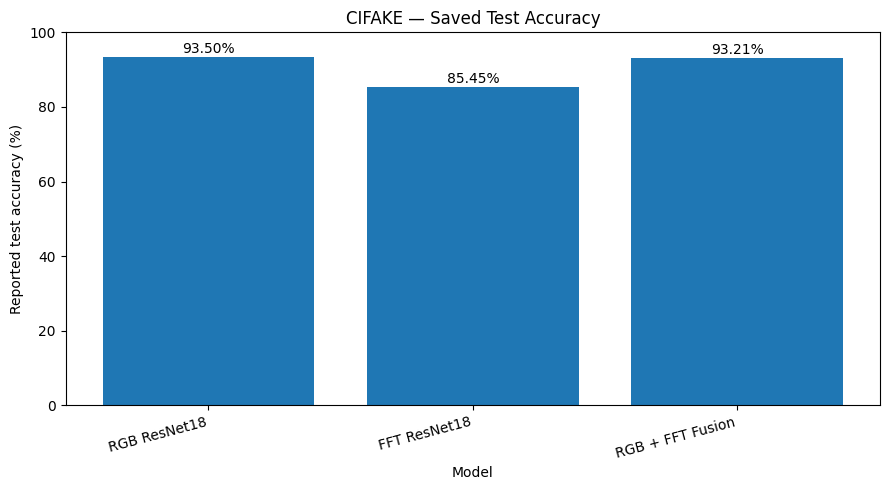

In [5]:

plot_df = metrics_df.dropna(subset=["accuracy"]).copy()

if not plot_df.empty:
    plt.figure(figsize=(9, 5))
    bars = plt.bar(plot_df["model"], plot_df["accuracy"] * 100)

    plt.ylabel("Reported test accuracy (%)")
    plt.xlabel("Model")
    plt.title("CIFAKE — Saved Test Accuracy")
    plt.ylim(0, 100)
    plt.xticks(rotation=15, ha="right")

    for bar, value in zip(bars, plot_df["accuracy"]):
        plt.text(
            bar.get_x() + bar.get_width() / 2,
            bar.get_height() + 1,
            f"{value:.2%}",
            ha="center",
        )

    plt.tight_layout()
    plt.savefig(OUT / "cifake_accuracy_comparison.png", dpi=180)
    plt.show()
else:
    print("No reported accuracy metrics found.")


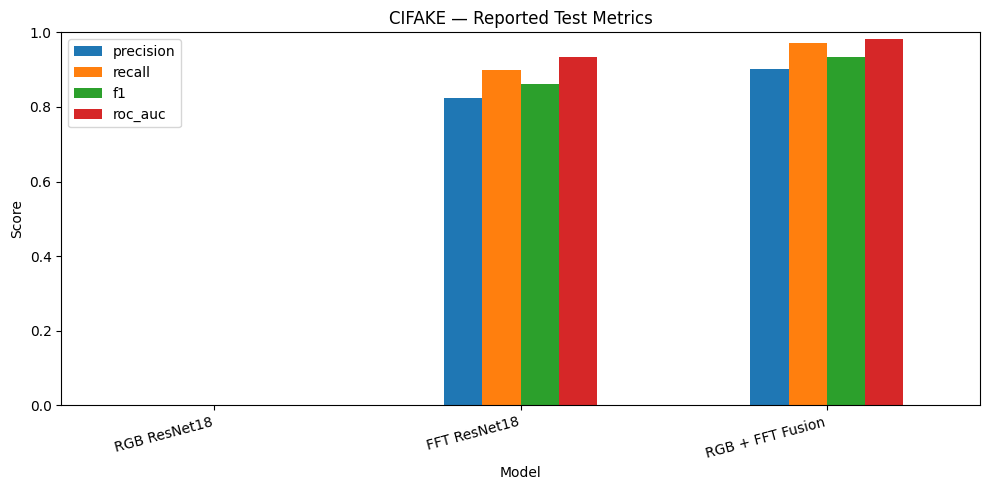

In [6]:

metric_columns = ["precision", "recall", "f1", "roc_auc"]

available = [
    col for col in metric_columns
    if col in metrics_df.columns and metrics_df[col].notna().any()
]

if available:
    ax = metrics_df.set_index("model")[available].plot(
        kind="bar", figsize=(10, 5), ylim=(0, 1)
    )
    ax.set_title("CIFAKE — Reported Test Metrics")
    ax.set_ylabel("Score")
    ax.set_xlabel("Model")
    plt.xticks(rotation=15, ha="right")
    plt.tight_layout()
    plt.savefig(OUT / "cifake_test_metrics_comparison.png", dpi=180)
    plt.show()
else:
    print("Precision, recall, F1 and ROC-AUC are not present in the saved reports.")


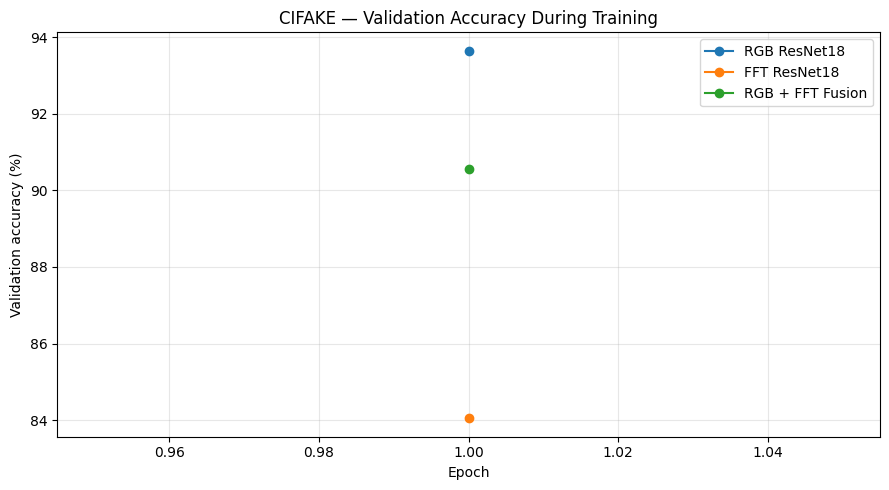

In [7]:

plt.figure(figsize=(9, 5))

for model_name, history in histories.items():
    epochs = [item["epoch"] for item in history]
    val_accuracy = []

    for item in history:
        # Some training scripts store validation accuracy directly;
        # others store it inside val_metrics.
        value = item.get("val_accuracy")
        if value is None:
            value = item.get("val_metrics", {}).get("accuracy")
        val_accuracy.append(value)

    valid = [
        (epoch, value)
        for epoch, value in zip(epochs, val_accuracy)
        if value is not None
    ]

    if valid:
        x, y = zip(*valid)
        plt.plot(x, np.array(y) * 100, marker="o", label=model_name)

plt.xlabel("Epoch")
plt.ylabel("Validation accuracy (%)")
plt.title("CIFAKE — Validation Accuracy During Training")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig(OUT / "cifake_validation_accuracy_history.png", dpi=180)
plt.show()


In [8]:
from pathlib import Path

ROOT = Path(r"E:\Projects\Deepfake detector")

CHECKPOINTS = {
    "CIFAKE RGB": ROOT / "experiments/rgb-baseline/cifake-image-v2/cifake-rgb-resnet18-best.pt",
    "CIFAKE FFT": ROOT / "experiments/fft-baseline/cifake-image-v2/cifake-fft-resnet18-best.pt",
    "CIFAKE RGB+FFT": ROOT / "experiments/fusion-baseline/cifake-image-v2/cifake-fusion-resnet18-best.pt",
}

for name, path in CHECKPOINTS.items():
    print(f"{name}: {'FOUND' if path.is_file() else 'MISSING'}")
    print(f"  {path}")

CIFAKE RGB: FOUND
  E:\Projects\Deepfake detector\experiments\rgb-baseline\cifake-image-v2\cifake-rgb-resnet18-best.pt
CIFAKE FFT: FOUND
  E:\Projects\Deepfake detector\experiments\fft-baseline\cifake-image-v2\cifake-fft-resnet18-best.pt
CIFAKE RGB+FFT: FOUND
  E:\Projects\Deepfake detector\experiments\fusion-baseline\cifake-image-v2\cifake-fusion-resnet18-best.pt


In [9]:
import json

for name, path in CHECKPOINTS.items():
    if not path.is_file():
        continue

    run_dir = path.parent
    print(f"\n--- {name} ---")

    config_path = next(run_dir.glob("*-config.json"), None)
    report_path = next(run_dir.glob("*-report.json"), None)

    if config_path and config_path.is_file():
        print("CONFIG:")
        print(json.dumps(json.loads(config_path.read_text()), indent=2))

    if report_path and report_path.is_file():
        print("REPORT:")
        print(json.dumps(json.loads(report_path.read_text()), indent=2))


--- CIFAKE RGB ---
CONFIG:
{
  "task": "cifake",
  "manifest_dir": "data\\metadata\\cifake-image-v2",
  "output_dir": "experiments\\rgb-baseline\\cifake-image-v2",
  "epochs": 1,
  "batch_size": 32,
  "learning_rate": 0.0001,
  "weight_decay": 0.0001,
  "seed": 42,
  "num_workers": 0,
  "max_records": null,
  "pretrained": true,
  "source_frame_manifest": null
}
REPORT:
{
  "task": "cifake",
  "records": {
    "train": 6318,
    "val": 1354,
    "test": 1354
  },
  "class_counts": {
    "train": {
      "real": 3160,
      "fake": 3158
    },
    "val": {
      "real": 677,
      "fake": 677
    },
    "test": {
      "real": 678,
      "fake": 676
    }
  },
  "group_counts": {
    "train": 6318,
    "val": 1354,
    "test": 1354
  },
  "duplicate_records": 0,
  "source_group_leakage": [],
  "image_files_validated": 9046,
  "device": "cpu",
  "pretrained_weights_requested": true,
  "pretrained_weights_loaded": true,
  "best_checkpoint": "experiments\\rgb-baseline\\cifake-image-v2\\ci

In [10]:
%pip install ipywidgets

Note: you may need to restart the kernel to use updated packages.


In [11]:
import sys
from pathlib import Path
import torch

ROOT = Path(r"E:\Projects\Deepfake detector")

if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from backend.training.rgb_baseline import build_model
from backend.training.fft_baseline import build_fft_model
from backend.training.fusion_baseline import RGBFFTFusionModel
from backend.app.preprocessing import preprocess_rgb
from backend.app.frequency import preprocess_fft

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")


def load_trained_model(checkpoint_path, model):
    checkpoint_path = Path(checkpoint_path)

    if not checkpoint_path.is_file():
        raise FileNotFoundError(
            f"Checkpoint not found: {checkpoint_path}"
        )

    # Use only with trusted checkpoints created by your own training pipeline.
    checkpoint = torch.load(
        checkpoint_path,
        map_location="cpu",
        weights_only=False,
    )

    if "model_state" not in checkpoint:
        raise KeyError(
            f"'model_state' missing from {checkpoint_path.name}"
        )

    model.load_state_dict(checkpoint["model_state"], strict=True)
    model = model.to(device)
    model.eval()

    print(
        f"Loaded: {checkpoint_path.name} | "
        f"epoch: {checkpoint.get('epoch', 'unknown')}"
    )
    return model


# Use CHECKPOINTS, which was defined in Cell 7.
rgb_model = load_trained_model(
    CHECKPOINTS["CIFAKE RGB"],
    build_model(pretrained=False),
)

fft_model = load_trained_model(
    CHECKPOINTS["CIFAKE FFT"],
    build_fft_model(pretrained=False)[0],
)

fusion_model = load_trained_model(
    CHECKPOINTS["CIFAKE RGB+FFT"],
    RGBFFTFusionModel(pretrained=False),
)

print("\nAll three CIFAKE models loaded successfully.")
print("Inference device:", device)

Loaded: cifake-rgb-resnet18-best.pt | epoch: 1
Loaded: cifake-fft-resnet18-best.pt | epoch: 1
Loaded: cifake-fusion-resnet18-best.pt | epoch: 1

All three CIFAKE models loaded successfully.
Inference device: cuda


In [12]:
from pathlib import Path
from IPython.display import display
from ipywidgets import FileUpload

image_picker = FileUpload(
    accept=".jpg,.jpeg,.png,.webp",
    multiple=False,
    description="Choose image"
)

display(image_picker)

FileUpload(value=(), accept='.jpg,.jpeg,.png,.webp', description='Choose image')

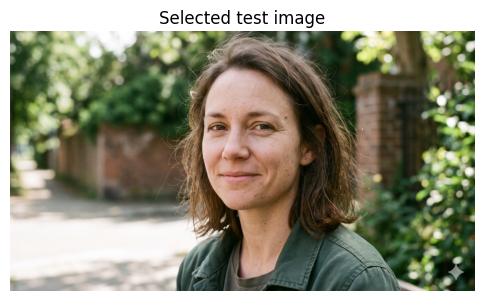

Image size: (2752, 1536)


In [14]:
from PIL import Image
from io import BytesIO
import matplotlib.pyplot as plt

def get_uploaded_image(upload_widget):
    value = upload_widget.value

    if not value:
        raise ValueError("Please select an image first.")

    # Supports common ipywidgets 7 and 8 upload formats.
    if isinstance(value, dict):
        item = next(iter(value.values()))
        content = item["content"]
    else:
        item = value[0]
        content = item["content"]

    image = Image.open(BytesIO(bytes(content))).convert("RGB")
    return image

sample_image = get_uploaded_image(image_picker)

plt.figure(figsize=(6, 6))
plt.imshow(sample_image)
plt.axis("off")
plt.title("Selected test image")
plt.show()

print("Image size:", sample_image.size)

In [15]:
import time
import numpy as np
import pandas as pd
import torch
from IPython.display import display


def prepare_image_inputs(image):
    rgb = torch.from_numpy(
        np.ascontiguousarray(preprocess_rgb(image))
    ).unsqueeze(0).to(device)

    fft = torch.from_numpy(
        np.ascontiguousarray(preprocess_fft(image))
    ).unsqueeze(0).to(device)

    return rgb, fft


def predict_one(model, *inputs):
    model.eval()

    if device.type == "cuda":
        torch.cuda.synchronize()

    start = time.perf_counter()

    with torch.inference_mode():
        logits = model(*inputs)

    if device.type == "cuda":
        torch.cuda.synchronize()

    elapsed_ms = (time.perf_counter() - start) * 1000

    if tuple(logits.shape) != (1, 2):
        raise ValueError(
            f"Expected model output shape (1, 2); got {tuple(logits.shape)}"
        )

    probabilities = torch.softmax(logits, dim=1)[0].cpu()
    predicted_index = int(probabilities.argmax().item())

    # Confirmed training label order must be 0=real, 1=fake.
    labels = ["Real", "AI-generated"]

    return {
        "Predicted class": labels[predicted_index],
        "Real score (%)": round(probabilities[0].item() * 100, 2),
        "AI-generated score (%)": round(probabilities[1].item() * 100, 2),
        "Inference time (ms)": round(elapsed_ms, 2),
    }


rgb_input, fft_input = prepare_image_inputs(sample_image)

predictors = {
    "RGB": lambda: predict_one(rgb_model, rgb_input),
    "FFT": lambda: predict_one(fft_model, fft_input),
    "RGB + FFT": lambda: predict_one(
        fusion_model, rgb_input, fft_input
    ),
}

rows = []

for name, predict in predictors.items():
    try:
        rows.append({"Model": name, **predict()})
    except Exception as exc:
        print(f"{name} failed: {type(exc).__name__}: {exc}")

if rows:
    results_df = pd.DataFrame(rows)
    display(results_df)
else:
    print("No predictions were generated.")

,Model,Predicted class,Real score (%),AI-generated score (%),Inference time (ms)
0,RGB,AI-generated,0.02,99.98,563.65
1,FFT,AI-generated,0.00,100.00,36.71
2,RGB + FFT,AI-generated,0.02,99.98,66.34


In [16]:
import torch
import pandas as pd
from IPython.display import display

rgb_input, fft_input = prepare_image_inputs(sample_image)

tests = {
    "RGB": (rgb_model, (rgb_input,)),
    "FFT": (fft_model, (fft_input,)),
    "RGB + FFT": (fusion_model, (rgb_input, fft_input)),
}

diagnostics = []

for name, (model, inputs) in tests.items():
    model.eval()

    with torch.inference_mode():
        logits = model(*inputs)
        probs = torch.softmax(logits, dim=1)[0].cpu()

    diagnostics.append({
        "Model": name,
        "Logit class 0": round(logits[0, 0].item(), 4),
        "Logit class 1": round(logits[0, 1].item(), 4),
        "Class 0 score (%)": round(probs[0].item() * 100, 2),
        "Class 1 score (%)": round(probs[1].item() * 100, 2),
        "Predicted index": int(probs.argmax().item()),
    })

display(pd.DataFrame(diagnostics))

,Model,Logit class 0,Logit class 1,Class 0 score (%),Class 1 score (%),Predicted index
0,RGB,-4.0065,4.4545,0.02,99.98,1
1,FFT,9.7190,24.4158,0.00,100.00,1
2,RGB + FFT,-12.8879,-4.3927,0.02,99.98,1


In [17]:
from pathlib import Path
import pandas as pd

manifest_path = ROOT / "data" / "metadata" / "cifake-image-v2" / "test.csv"

if manifest_path.exists():
    df = pd.read_csv(manifest_path)
    print("Columns:", df.columns.tolist())
    display(df.head(10))
else:
    print("Manifest not found:", manifest_path)
    print("Use the actual CIFAKE test.csv path shown in your inventory.")

Columns: ['path', 'label_name', 'label', 'group_id', 'sha256', 'width', 'height', 'format', 'split']


,path,label_name,label,group_id,sha256,width,height,format,split
0,data\metadata\cifake-image-v2\training-source\...,real,0,real/382,259bac34cccc1da7c4b67c41ef72b776fe6042c01d3e40...,32,32,JPEG,test
1,data\metadata\cifake-image-v2\training-source\...,real,0,real/1935,89fc6479cf9162d18999e882da42caab8c5f00666cd673...,32,32,JPEG,test
2,data\metadata\cifake-image-v2\training-source\...,real,0,real/3571,9280f4962eb3732a58ab6a43f80974c3db626a6f7663d2...,32,32,JPEG,test
3,data\metadata\cifake-image-v2\training-source\...,real,0,real/2705,1459e2e0e32eba085481780d80b1d388b340af91c55696...,32,32,JPEG,test
4,data\metadata\cifake-image-v2\training-source\...,real,0,real/1794,8bc0c16d0d25d1024e3c02aa30dc7cc927aad2070d4887...,32,32,JPEG,test
5,data\metadata\cifake-image-v2\training-source\...,real,0,real/3071,5871b64b4af5c934a2abd13c77c9f4432e6ec0e3978c8d...,32,32,JPEG,test
6,data\metadata\cifake-image-v2\training-source\...,real,0,real/777,a5461549ef5f25bcc7cf20a0531cbd788d926db61417fb...,32,32,JPEG,test
7,data\metadata\cifake-image-v2\training-source\...,real,0,real/3460,3a8c3de5e60a8a66792e07fd286bf717488e174100252d...,32,32,JPEG,test
8,data\metadata\cifake-image-v2\training-source\...,real,0,real/690,a256e2444adb54cc2e17ce0d15871d79757698fbb1c0a5...,32,32,JPEG,test
9,data\metadata\cifake-image-v2\training-source\...,real,0,real/1456,508ed986d6bd829276512e80b3c280f9ad53aa08c15c9d...,32,32,JPEG,test


In [18]:
manifest_path = ROOT / "data" / "metadata" / "cifake-image-v2" / "test.csv"

df = pd.read_csv(manifest_path)

print("Label mapping:")
print(
    df.groupby(["label", "label_name"])
      .size()
      .reset_index(name="count")
      .sort_values("label")
      .to_string(index=False)
)

print("\nUnique labels:", sorted(df["label"].unique()))

Label mapping:
 label label_name  count
     0       real    678
     1       fake    676

Unique labels: [np.int64(0), np.int64(1)]


In [19]:
from PIL import Image
import numpy as np
import pandas as pd
import torch

manifest_path = ROOT / "data" / "metadata" / "cifake-image-v2" / "test.csv"
df = pd.read_csv(manifest_path)

print(df.groupby(["label", "label_name"]).size())

# Select 10 examples from each class
sample_rows = pd.concat([
    df[df["label_name"] == "real"].head(10),
    df[df["label_name"] == "fake"].head(10),
], ignore_index=True)

results = []

for _, row in sample_rows.iterrows():
    image_path = ROOT / row["path"]

    if not image_path.exists():
        print("Missing image:", image_path)
        continue

    image = Image.open(image_path).convert("RGB")

    rgb_input, fft_input = prepare_image_inputs(image)

    model_inputs = {
        "RGB": (rgb_model, (rgb_input,)),
        "FFT": (fft_model, (fft_input,)),
        "RGB + FFT": (fusion_model, (rgb_input, fft_input)),
    }

    result = {
        "Actual label": row["label_name"],
        "Image": str(row["path"]),
    }

    for model_name, (model, inputs) in model_inputs.items():
        model.eval()

        with torch.inference_mode():
            logits = model(*inputs)
            prediction = int(logits.argmax(dim=1).item())

        result[model_name] = prediction

    results.append(result)

results_df = pd.DataFrame(results)
display(results_df)

label  label_name
0      real          678
1      fake          676
dtype: int64


,Actual label,Image,RGB,FFT,RGB + FFT
0,real,data\metadata\cifake-image-v2\training-source\...,0,1,1
1,real,data\metadata\cifake-image-v2\training-source\...,0,1,0
2,real,data\metadata\cifake-image-v2\training-source\...,0,1,0
3,real,data\metadata\cifake-image-v2\training-source\...,0,1,0
4,real,data\metadata\cifake-image-v2\training-source\...,0,1,0
5,real,data\metadata\cifake-image-v2\training-source\...,0,1,0
6,real,data\metadata\cifake-image-v2\training-source\...,0,1,0
7,real,data\metadata\cifake-image-v2\training-source\...,0,1,0
8,real,data\metadata\cifake-image-v2\training-source\...,0,1,0
9,real,data\metadata\cifake-image-v2\training-source\...,0,1,0


In [20]:
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

# Verify class mapping before interpreting the results
print(
    df.groupby(["label", "label_name"]).size()
      .reset_index(name="count")
      .sort_values("label")
)

actual = results_df["Actual label"].map({"real": 0, "fake": 1})

for model_name in ["RGB", "FFT", "RGB + FFT"]:
    predicted = results_df[model_name]

    print(f"\n--- {model_name} ---")
    print("Accuracy:", round(accuracy_score(actual, predicted), 3))
    print("Confusion matrix (real=0, fake=1):")
    print(confusion_matrix(actual, predicted, labels=[0, 1]))
    print(classification_report(
        actual,
        predicted,
        labels=[0, 1],
        target_names=["Real", "AI-generated"],
        zero_division=0,
    ))

   label label_name  count
0      0       real    678
1      1       fake    676

--- RGB ---
Accuracy: 1.0
Confusion matrix (real=0, fake=1):
[[10  0]
 [ 0 10]]
              precision    recall  f1-score   support

        Real       1.00      1.00      1.00        10
AI-generated       1.00      1.00      1.00        10

    accuracy                           1.00        20
   macro avg       1.00      1.00      1.00        20
weighted avg       1.00      1.00      1.00        20


--- FFT ---
Accuracy: 0.5
Confusion matrix (real=0, fake=1):
[[ 0 10]
 [ 0 10]]
              precision    recall  f1-score   support

        Real       0.00      0.00      0.00        10
AI-generated       0.50      1.00      0.67        10

    accuracy                           0.50        20
   macro avg       0.25      0.50      0.33        20
weighted avg       0.25      0.50      0.33        20


--- RGB + FFT ---
Accuracy: 0.85
Confusion matrix (real=0, fake=1):
[[9 1]
 [2 8]]
              preci

In [21]:
from PIL import Image
import pandas as pd

print("Original image size:", sample_image.size)
print("Original image mode:", sample_image.mode)

resized_image = sample_image.convert("RGB").resize(
    (224, 224),
    Image.Resampling.BILINEAR,
)

comparison = []

for image_name, image in [
    ("Original upload", sample_image),
    ("Resized to 224x224", resized_image),
]:
    rgb_input, fft_input = prepare_image_inputs(image)

    for model_name, model, inputs in [
        ("RGB", rgb_model, (rgb_input,)),
        ("FFT", fft_model, (fft_input,)),
        ("RGB + FFT", fusion_model, (rgb_input, fft_input)),
    ]:
        model.eval()

        with torch.inference_mode():
            logits = model(*inputs)
            probabilities = torch.softmax(logits, dim=1)[0].cpu()

        comparison.append({
            "Image": image_name,
            "Model": model_name,
            "Real score (%)": round(probabilities[0].item() * 100, 2),
            "AI-generated score (%)": round(probabilities[1].item() * 100, 2),
        })

display(pd.DataFrame(comparison))

Original image size: (2752, 1536)
Original image mode: RGB


,Image,Model,Real score (%),AI-generated score (%)
0,Original upload,RGB,0.02,99.98
1,Original upload,FFT,0.00,100.00
2,Original upload,RGB + FFT,0.02,99.98
3,Resized to 224x224,RGB,0.02,99.98
4,Resized to 224x224,FFT,0.00,100.00
5,Resized to 224x224,RGB + FFT,0.02,99.98


In [22]:
from pathlib import Path
from PIL import Image
from torch.utils.data import DataLoader, Dataset
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    classification_report,
    roc_auc_score,
)
import numpy as np
import pandas as pd
import torch


class CIFAKETestDataset(Dataset):
    def __init__(self, dataframe, root):
        self.df = dataframe.reset_index(drop=True)
        self.root = Path(root)

    def __len__(self):
        return len(self.df)

    def __getitem__(self, index):
        row = self.df.iloc[index]
        path = self.root / row["path"]

        image = Image.open(path).convert("RGB")
        rgb, fft = prepare_image_inputs(image)

        return (
            rgb.squeeze(0),
            fft.squeeze(0),
            int(row["label"]),
        )


manifest_path = ROOT / "data" / "metadata" / "cifake-image-v2" / "test.csv"
test_df = pd.read_csv(manifest_path)

print("Test samples:", len(test_df))
print(test_df.groupby(["label", "label_name"]).size())

test_dataset = CIFAKETestDataset(test_df, ROOT)
test_loader = DataLoader(test_dataset, batch_size=8, shuffle=False)

models = {
    "RGB": rgb_model,
    "FFT": fft_model,
    "RGB + FFT": fusion_model,
}

all_results = {name: {"y": [], "pred": [], "score": []} for name in models}

for model in models.values():
    model.eval()

with torch.inference_mode():
    for rgb, fft, labels in test_loader:
        rgb = rgb.to(device)
        fft = fft.to(device)

        inputs_by_model = {
            "RGB": (rgb,),
            "FFT": (fft,),
            "RGB + FFT": (rgb, fft),
        }

        for name, model in models.items():
            logits = model(*inputs_by_model[name])
            probabilities = torch.softmax(logits, dim=1)

            all_results[name]["y"].extend(labels.tolist())
            all_results[name]["pred"].extend(
                logits.argmax(dim=1).cpu().tolist()
            )
            all_results[name]["score"].extend(
                probabilities[:, 1].cpu().tolist()
            )

summary = []

for name, result in all_results.items():
    y = np.asarray(result["y"])
    pred = np.asarray(result["pred"])
    score = np.asarray(result["score"])

    summary.append({
        "Model": name,
        "Accuracy (%)": round(accuracy_score(y, pred) * 100, 2),
        "ROC-AUC": round(roc_auc_score(y, score), 4),
    })

    print(f"\n===== {name} =====")
    print("Confusion matrix (rows=actual, columns=predicted):")
    print(confusion_matrix(y, pred, labels=[0, 1]))
    print(classification_report(
        y,
        pred,
        labels=[0, 1],
        target_names=["Real", "AI-generated"],
        zero_division=0,
    ))

display(pd.DataFrame(summary))

Test samples: 1354
label  label_name
0      real          678
1      fake          676
dtype: int64

===== RGB =====
Confusion matrix (rows=actual, columns=predicted):
[[617  61]
 [ 27 649]]
              precision    recall  f1-score   support

        Real       0.96      0.91      0.93       678
AI-generated       0.91      0.96      0.94       676

    accuracy                           0.94      1354
   macro avg       0.94      0.94      0.93      1354
weighted avg       0.94      0.94      0.93      1354


===== FFT =====
Confusion matrix (rows=actual, columns=predicted):
[[  0 678]
 [  0 676]]
              precision    recall  f1-score   support

        Real       0.00      0.00      0.00       678
AI-generated       0.50      1.00      0.67       676

    accuracy                           0.50      1354
   macro avg       0.25      0.50      0.33      1354
weighted avg       0.25      0.50      0.33      1354


===== RGB + FFT =====
Confusion matrix (rows=actual, columns=pr

,Model,Accuracy (%),ROC-AUC
0,RGB,93.50,0.9833
1,FFT,49.93,0.5007
2,RGB + FFT,86.26,0.9750


## 8. Reproducible evaluation and external-dataset testing

This notebook currently contains saved benchmark reports and a full CIFAKE test-manifest evaluation. The full test set has 1,354 images (678 real, 676 fake). The currently saved inference results are useful, but results on CIFAKE alone do **not** establish generalization to ordinary photographs, faces, or images from different generators.

This section adds:
- reproducible per-image predictions and complete metrics;
- confusion matrices, ROC and precision–recall curves;
- error analysis with paths to false positives/false negatives;
- an optional external-test manifest interface;
- dataset inventory and runtime notes.

**Important:** this notebook does not automatically download external datasets. Dataset access, license terms, split definitions, and any required preprocessing should be checked before using them. Never evaluate on training images or tune thresholds on the final test set.

In [23]:
# Core imports and reproducibility settings for the enhanced evaluation cells.
import json
import time
import random
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
import torch
from sklearn.metrics import (
    accuracy_score, balanced_accuracy_score, precision_score, recall_score,
    f1_score, confusion_matrix, classification_report, roc_auc_score,
    average_precision_score, roc_curve, precision_recall_curve,
    ConfusionMatrixDisplay
)

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

ROOT = Path(r"E:\Projects\Deepfake detector")
EVAL_OUT = ROOT / "experiments" / "benchmark-visualizations" / "enhanced"
EVAL_OUT.mkdir(parents=True, exist_ok=True)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Project root:", ROOT)
print("Output folder:", EVAL_OUT)
print("Device:", DEVICE)
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

Project root: E:\Projects\Deepfake detector
Output folder: E:\Projects\Deepfake detector\experiments\benchmark-visualizations\enhanced
Device: cuda
GPU: NVIDIA GeForce RTX 3050 6GB Laptop GPU


### 8.1 Dataset inventory and manifest audit

Use this to record which manifests are available and whether their labels are balanced. A manifest should have `path` and `label_name` or `label` columns. For external testing, labels must mean `real=0` and `fake=1`; do not silently assume a dataset's original class IDs have that meaning.

In [24]:
def audit_manifest(manifest_path, dataset_name="dataset", root=ROOT):
    manifest_path = Path(manifest_path)
    if not manifest_path.is_absolute():
        manifest_path = root / manifest_path
    if not manifest_path.exists():
        print(f"[MISSING] {dataset_name}: {manifest_path}")
        return None

    frame = pd.read_csv(manifest_path)
    print(f"\n=== {dataset_name} ===")
    print("Manifest:", manifest_path)
    print("Rows:", len(frame))
    print("Columns:", frame.columns.tolist())

    label_col = "label_name" if "label_name" in frame.columns else (
        "label" if "label" in frame.columns else None
    )
    if label_col:
        print("Label counts:")
        display(frame[label_col].value_counts(dropna=False).to_frame("count"))
    else:
        print("WARNING: no obvious label column found.")

    if "path" in frame.columns:
        resolved = []
        for value in frame["path"].dropna():
            candidate = Path(str(value))
            if not candidate.is_absolute():
                candidate = root / candidate
            resolved.append(candidate.exists())
        print(f"Path existence: {sum(resolved)}/{len(resolved)}")
    else:
        print("WARNING: no path column found.")
    return frame

cifake_test_manifest = ROOT / "data" / "metadata" / "cifake-image-v2" / "test.csv"
cifake_audit_df = audit_manifest(cifake_test_manifest, "CIFAKE test")


=== CIFAKE test ===
Manifest: E:\Projects\Deepfake detector\data\metadata\cifake-image-v2\test.csv
Rows: 1354
Columns: ['path', 'label_name', 'label', 'group_id', 'sha256', 'width', 'height', 'format', 'split']
Label counts:


,count
label_name,
real,678
fake,676


Path existence: 1354/1354


### 8.2 Full CIFAKE test evaluation with saved per-image predictions

This cell re-runs inference and saves one row per test image. It uses the project's existing `prepare_image_inputs`, which calls the canonical RGB and FFT preprocessing functions from the application. The output includes class-1 scores so ROC-AUC and average precision can be calculated.

The model score is not a calibrated probability of truth; interpret it as a model output score.

In [25]:
# Ensure model dictionary matches the models loaded earlier in this notebook.
EVAL_MODELS = {
    "RGB": rgb_model,
    "FFT": fft_model,
    "RGB + FFT": fusion_model,
}

def resolve_manifest_image(path_value, root=ROOT):
    p = Path(str(path_value))
    return p if p.is_absolute() else root / p

def run_manifest_evaluation(frame, models, dataset_name="CIFAKE", root=ROOT):
    required = {"path"}
    if not required.issubset(frame.columns):
        raise ValueError(f"Manifest needs columns: {sorted(required)}")

    if "label_name" in frame.columns:
        label_text = frame["label_name"].astype(str).str.strip().str.lower()
        mapping = {"real": 0, "fake": 1, "ai-generated": 1, "ai_generated": 1}
        unknown = sorted(set(label_text.unique()) - set(mapping))
        if unknown:
            raise ValueError(f"Unknown label_name values: {unknown}. Map these explicitly.")
        y_true = label_text.map(mapping).to_numpy(dtype=int)
    elif "label" in frame.columns:
        y_true = pd.to_numeric(frame["label"], errors="raise").to_numpy(dtype=int)
        if not set(np.unique(y_true)).issubset({0, 1}):
            raise ValueError("Numeric labels must be explicitly mapped to 0=real, 1=fake.")
    else:
        raise ValueError("Manifest must contain label_name or label.")

    records = []
    skipped = []
    for idx, row in frame.reset_index(drop=True).iterrows():
        image_path = resolve_manifest_image(row["path"], root)
        if not image_path.is_file():
            skipped.append((idx, str(image_path), "missing"))
            continue
        try:
            with Image.open(image_path) as im:
                image = im.convert("RGB")
            rgb_tensor, fft_tensor = prepare_image_inputs(image)
            model_inputs = {
                "RGB": (rgb_tensor,),
                "FFT": (fft_tensor,),
                "RGB + FFT": (rgb_tensor, fft_tensor),
            }
            for model_name, model in models.items():
                model.eval()
                with torch.inference_mode():
                    logits = model(*model_inputs[model_name])
                    probs = torch.softmax(logits, dim=1)[0].detach().cpu().numpy()
                records.append({
                    "dataset": dataset_name,
                    "row_index": idx,
                    "path": str(image_path),
                    "actual": int(y_true[idx]),
                    "actual_name": "fake" if int(y_true[idx]) == 1 else "real",
                    "model": model_name,
                    "predicted": int(np.argmax(probs)),
                    "real_score": float(probs[0]),
                    "fake_score": float(probs[1]),
                })
        except Exception as exc:
            skipped.append((idx, str(image_path), repr(exc)))

    predictions = pd.DataFrame(records)
    if predictions.empty:
        raise RuntimeError("No predictions were produced. Check manifest paths and preprocessing.")
    print(f"Predicted rows: {len(predictions)}; skipped images: {len(skipped)}")
    if skipped:
        display(pd.DataFrame(skipped, columns=["row_index", "path", "reason"]).head(20))
    return predictions

# Re-run only when desired; it can take a little time because each image is processed.
cifake_predictions = run_manifest_evaluation(
    cifake_audit_df, EVAL_MODELS, dataset_name="CIFAKE-test", root=ROOT
)
pred_path = EVAL_OUT / "cifake_test_predictions.csv"
cifake_predictions.to_csv(pred_path, index=False)
print("Saved per-image predictions:", pred_path)

Predicted rows: 4062; skipped images: 0
Saved per-image predictions: E:\Projects\Deepfake detector\experiments\benchmark-visualizations\enhanced\cifake_test_predictions.csv


### 8.3 Detailed metrics, confusion matrices, ROC and precision–recall curves

Metrics are computed separately for each model. Because this is the CIFAKE test set, do not use it repeatedly to tune a threshold and then report it as an untouched final evaluation.


===== RGB | CIFAKE-test =====
              precision    recall  f1-score   support

        Real       0.96      0.91      0.93       678
AI-generated       0.91      0.96      0.94       676

    accuracy                           0.94      1354
   macro avg       0.94      0.94      0.93      1354
weighted avg       0.94      0.94      0.93      1354



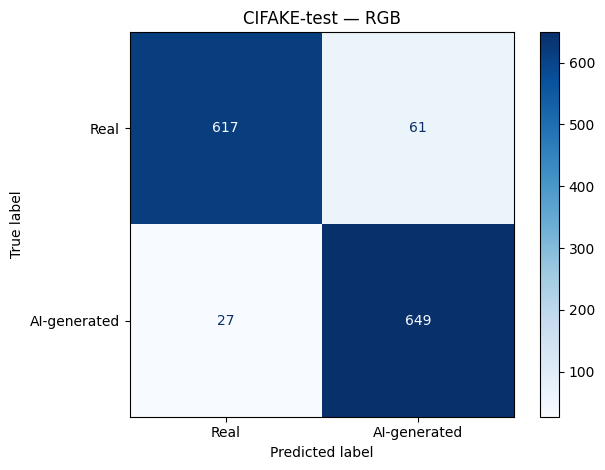


===== FFT | CIFAKE-test =====
              precision    recall  f1-score   support

        Real       0.00      0.00      0.00       678
AI-generated       0.50      1.00      0.67       676

    accuracy                           0.50      1354
   macro avg       0.25      0.50      0.33      1354
weighted avg       0.25      0.50      0.33      1354



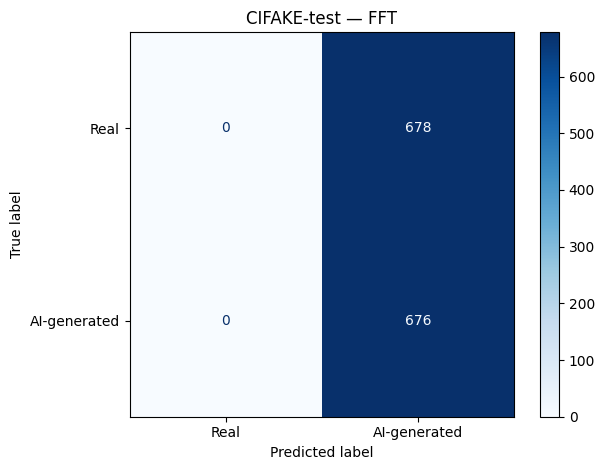


===== RGB + FFT | CIFAKE-test =====
              precision    recall  f1-score   support

        Real       0.98      0.74      0.84       678
AI-generated       0.79      0.98      0.88       676

    accuracy                           0.86      1354
   macro avg       0.89      0.86      0.86      1354
weighted avg       0.89      0.86      0.86      1354



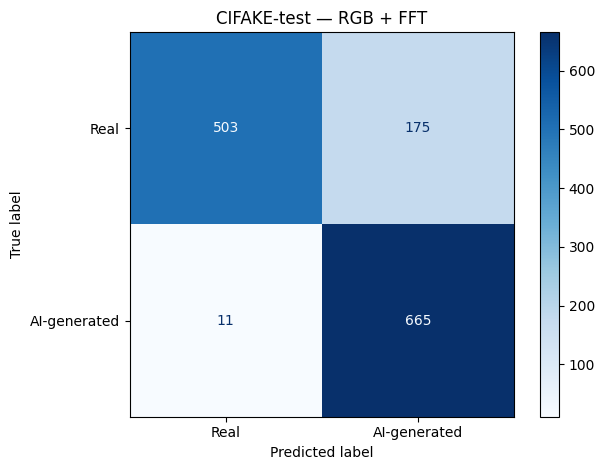

,dataset,model,n,accuracy,balanced_accuracy,precision_fake,recall_fake,f1_fake,roc_auc,average_precision
0,CIFAKE-test,RGB,1354,0.935007,0.935044,0.914085,0.960059,0.936508,0.983287,0.982653
1,CIFAKE-test,FFT,1354,0.499261,0.500000,0.499261,1.000000,0.666010,0.500737,0.499630
2,CIFAKE-test,RGB + FFT,1354,0.862629,0.862808,0.791667,0.983728,0.877309,0.974952,0.975087


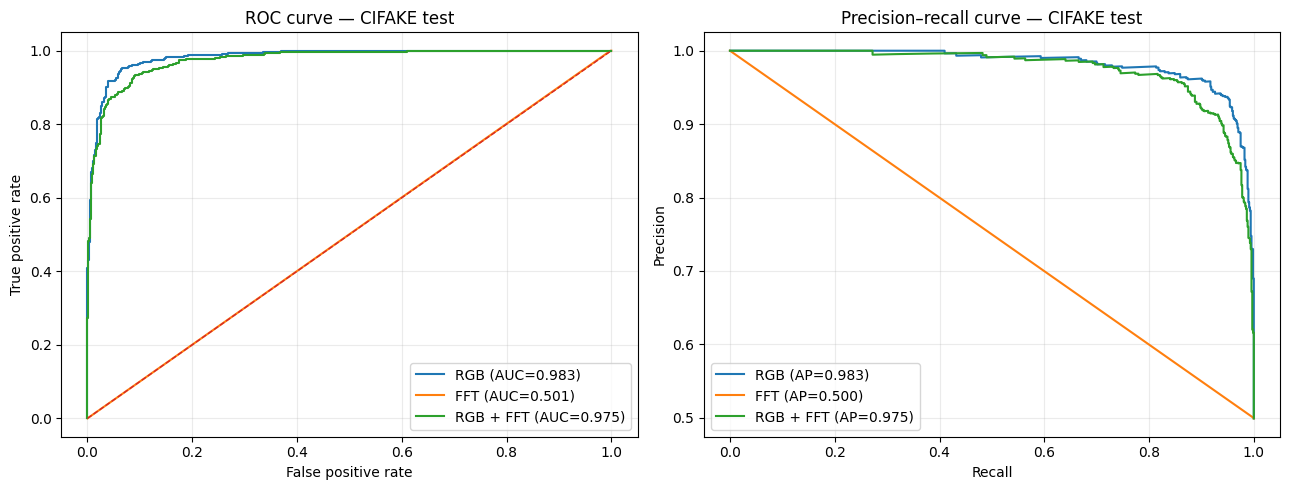

In [26]:
def summarize_predictions(predictions):
    summaries = []
    for model_name, group in predictions.groupby("model", sort=False):
        y = group["actual"].to_numpy(dtype=int)
        pred = group["predicted"].to_numpy(dtype=int)
        score = group["fake_score"].to_numpy(dtype=float)
        summary = {
            "dataset": group["dataset"].iloc[0],
            "model": model_name,
            "n": len(group),
            "accuracy": accuracy_score(y, pred),
            "balanced_accuracy": balanced_accuracy_score(y, pred),
            "precision_fake": precision_score(y, pred, zero_division=0),
            "recall_fake": recall_score(y, pred, zero_division=0),
            "f1_fake": f1_score(y, pred, zero_division=0),
            "roc_auc": roc_auc_score(y, score) if len(np.unique(y)) == 2 else np.nan,
            "average_precision": average_precision_score(y, score) if len(np.unique(y)) == 2 else np.nan,
        }
        summaries.append(summary)

        print(f"\n===== {model_name} | {summary['dataset']} =====")
        print(classification_report(
            y, pred, labels=[0, 1],
            target_names=["Real", "AI-generated"],
            zero_division=0
        ))
        cm = confusion_matrix(y, pred, labels=[0, 1])
        ConfusionMatrixDisplay(cm, display_labels=["Real", "AI-generated"]).plot(
            values_format="d", cmap="Blues"
        )
        plt.title(f"{summary['dataset']} — {model_name}")
        plt.tight_layout()
        plt.show()

    return pd.DataFrame(summaries)

detailed_metrics = summarize_predictions(cifake_predictions)
display(detailed_metrics)
detailed_metrics.to_csv(EVAL_OUT / "cifake_detailed_metrics.csv", index=False)

# ROC and precision-recall curves (scores are not calibrated probabilities).
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for model_name, group in cifake_predictions.groupby("model", sort=False):
    y = group["actual"].to_numpy(dtype=int)
    score = group["fake_score"].to_numpy(dtype=float)
    if len(np.unique(y)) < 2:
        continue
    fpr, tpr, _ = roc_curve(y, score)
    axes[0].plot(fpr, tpr, label=f"{model_name} (AUC={roc_auc_score(y, score):.3f})")
    precision, recall, _ = precision_recall_curve(y, score)
    axes[1].plot(recall, precision, label=f"{model_name} (AP={average_precision_score(y, score):.3f})")

axes[0].plot([0, 1], [0, 1], linestyle="--", linewidth=1)
axes[0].set(title="ROC curve — CIFAKE test", xlabel="False positive rate", ylabel="True positive rate")
axes[1].set(title="Precision–recall curve — CIFAKE test", xlabel="Recall", ylabel="Precision")
for ax in axes:
    ax.legend()
    ax.grid(alpha=0.25)
plt.tight_layout()
plt.savefig(EVAL_OUT / "cifake_roc_pr_curves.png", dpi=160)
plt.show()

### 8.4 Error analysis: false positives and false negatives

A false positive is a real image predicted as fake. A false negative is a fake image predicted as real. Review errors for dataset artifacts and distribution differences, but do not use these test examples to silently retrain or tune and then continue calling the same set an unbiased test set.

,error_type,actual_name,predicted,fake_score,path
1779,False positive (real -> fake),real,1,0.999357,E:\Projects\Deepfake detector\data\metadata\ci...
147,False positive (real -> fake),real,1,0.999037,E:\Projects\Deepfake detector\data\metadata\ci...
435,False positive (real -> fake),real,1,0.998613,E:\Projects\Deepfake detector\data\metadata\ci...
1986,False positive (real -> fake),real,1,0.995872,E:\Projects\Deepfake detector\data\metadata\ci...
1233,False positive (real -> fake),real,1,0.989892,E:\Projects\Deepfake detector\data\metadata\ci...
297,False positive (real -> fake),real,1,0.989477,E:\Projects\Deepfake detector\data\metadata\ci...
456,False positive (real -> fake),real,1,0.988004,E:\Projects\Deepfake detector\data\metadata\ci...
1740,False positive (real -> fake),real,1,0.985846,E:\Projects\Deepfake detector\data\metadata\ci...
1689,False positive (real -> fake),real,1,0.985771,E:\Projects\Deepfake detector\data\metadata\ci...
42,False positive (real -> fake),real,1,0.982864,E:\Projects\Deepfake detector\data\metadata\ci...


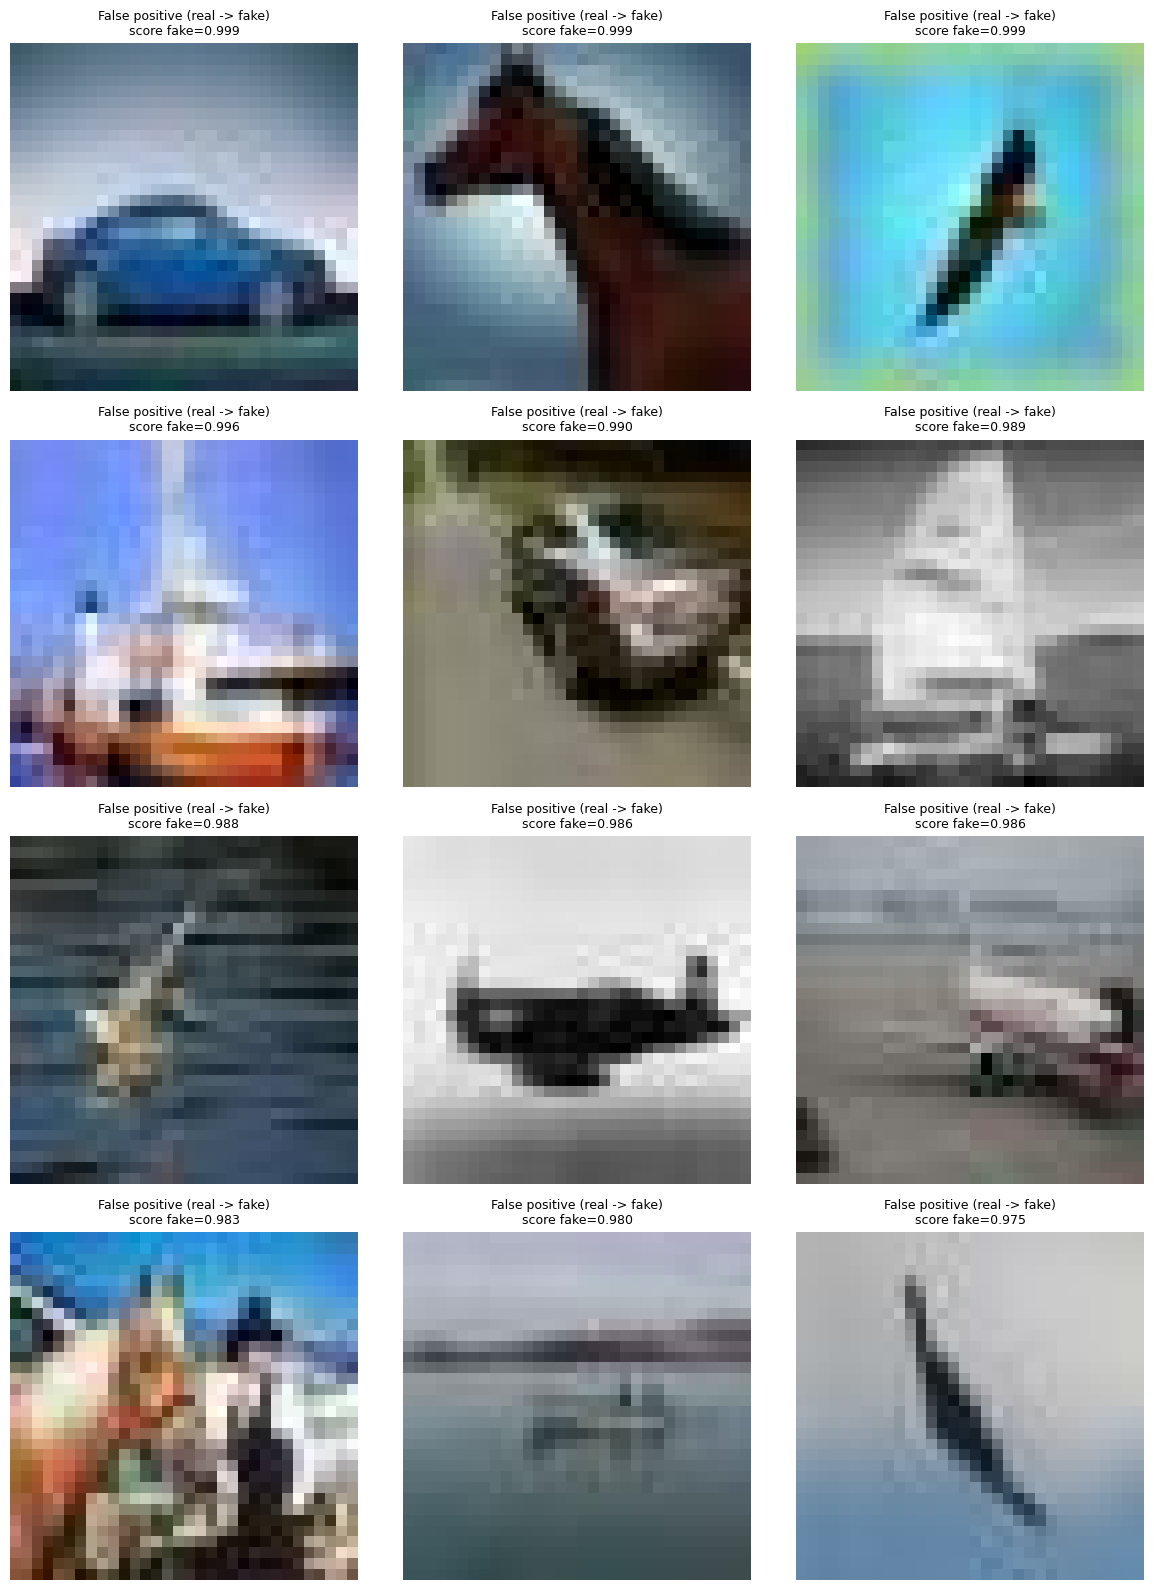

In [27]:
def show_error_gallery(predictions, model_name="RGB", limit=12):
    subset = predictions[predictions["model"] == model_name].copy()
    errors = subset[subset["actual"] != subset["predicted"]].copy()
    if errors.empty:
        print(f"No errors found for {model_name} in this evaluation.")
        return errors

    errors["error_type"] = np.where(
        (errors["actual"] == 0) & (errors["predicted"] == 1),
        "False positive (real -> fake)",
        "False negative (fake -> real)",
    )
    errors = errors.sort_values("fake_score", ascending=False).head(limit)
    display(errors[["error_type", "actual_name", "predicted", "fake_score", "path"]])

    n = len(errors)
    cols = 3
    rows = int(np.ceil(n / cols))
    fig, axes = plt.subplots(rows, cols, figsize=(12, 4 * rows))
    axes = np.array(axes).reshape(-1)
    for ax in axes:
        ax.axis("off")
    for ax, (_, item) in zip(axes, errors.iterrows()):
        try:
            with Image.open(item["path"]) as im:
                ax.imshow(im.convert("RGB"))
            ax.set_title(
                f"{item['error_type']}\nscore fake={item['fake_score']:.3f}",
                fontsize=9
            )
            ax.axis("off")
        except Exception as exc:
            ax.set_title(f"Could not open image: {exc}", fontsize=8)
    plt.tight_layout()
    plt.show()
    return errors

# Change model_name to "FFT" or "RGB + FFT" to inspect those models.
rgb_errors = show_error_gallery(cifake_predictions, model_name="RGB", limit=12)

### 8.5 External/standard dataset evaluation

For a stronger test of generalization, use a **separate, held-out dataset** whose source and labels are documented. Recommended choices depend on the intended task:

- **CIFAKE**: useful for synthetic-vs-real image classification, but narrow and not a substitute for external testing.
- **GenImage**: broad AI-generated image benchmark with real and generated images from multiple generators. Use a fixed, held-out split and document the generator/source.
- **FaceForensics++**: manipulated-face *video* benchmark. For this image model, evaluate extracted frames with a manifest and avoid placing frames from the same source video across train and test.
- **Celeb-DF** or **DFDC**: video deepfake datasets; require careful frame sampling and video-level grouping.

These datasets have different domains and may have different licensing/access rules. Do not claim that this notebook has tested them until you configure a manifest and the evaluation finishes successfully. An external score can be much lower than CIFAKE and still be a valuable finding about domain shift.

In [28]:
# Configure external datasets only after downloading/accessing them under their terms.
# Expected CSV columns:
#   path       : image path, absolute or relative to ROOT
#   label_name : "real" or "fake"
#
# Example template; keep enabled=False until the CSV is real and verified.
EXTERNAL_DATASETS = {
    # "GenImage-heldout": {
    #     "enabled": False,
    #     "manifest": "data/external/genimage-heldout.csv",
    #     "root": ROOT,
    # },
    # "FaceForensicsPP-frames-heldout": {
    #     "enabled": False,
    #     "manifest": "data/external/faceforensicspp-frames-heldout.csv",
    #     "root": ROOT,
    # },
}

external_prediction_frames = []
for dataset_name, config in EXTERNAL_DATASETS.items():
    if not config.get("enabled", False):
        print(f"Skipping {dataset_name}: not enabled.")
        continue

    manifest = Path(config["manifest"])
    if not manifest.is_absolute():
        manifest = ROOT / manifest
    if not manifest.is_file():
        print(f"Skipping {dataset_name}: manifest not found: {manifest}")
        continue

    external_df = pd.read_csv(manifest)
    print(f"\nAuditing external dataset: {dataset_name}")
    audit_manifest(manifest, dataset_name, root=config.get("root", ROOT))
    pred_df = run_manifest_evaluation(
        external_df,
        EVAL_MODELS,
        dataset_name=dataset_name,
        root=config.get("root", ROOT),
    )
    external_prediction_frames.append(pred_df)

if external_prediction_frames:
    external_predictions = pd.concat(external_prediction_frames, ignore_index=True)
    external_metrics = summarize_predictions(external_predictions)
    display(external_metrics)
    external_predictions.to_csv(EVAL_OUT / "external_predictions.csv", index=False)
    external_metrics.to_csv(EVAL_OUT / "external_metrics.csv", index=False)
else:
    print(
        "No external dataset evaluated yet. Configure a verified held-out manifest "
        "in EXTERNAL_DATASETS to run external testing."
    )

No external dataset evaluated yet. Configure a verified held-out manifest in EXTERNAL_DATASETS to run external testing.


### 8.6 Confidence and robustness checks

Softmax outputs can be overconfident and are not automatically calibrated. Report score distributions alongside classification metrics. A simple resize/compression robustness check can reveal sensitivity, but it must not be confused with external-dataset evaluation.

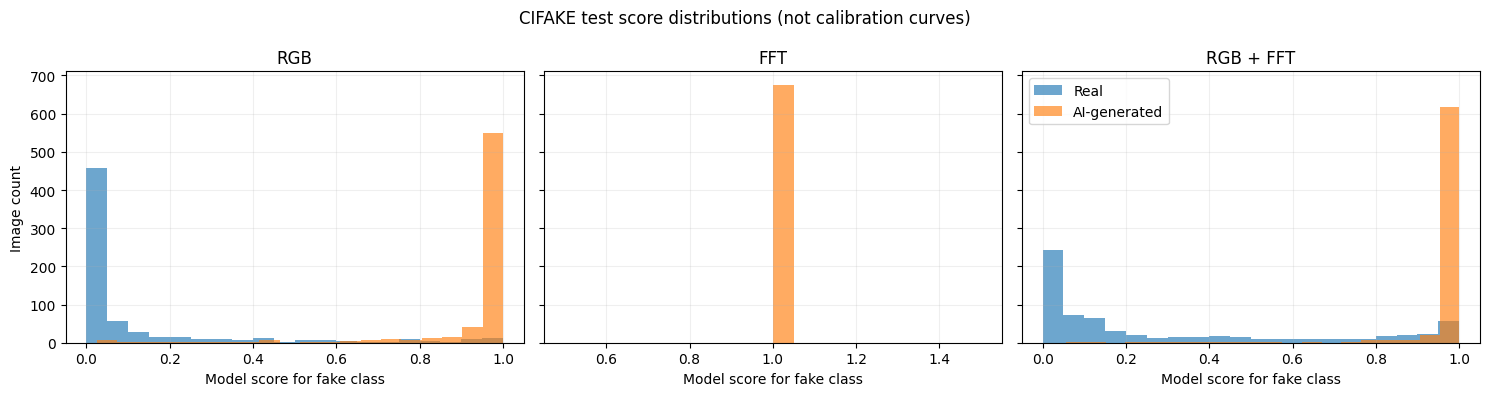

In [29]:
# Score distribution by actual class for the CIFAKE test set.
fig, axes = plt.subplots(1, 3, figsize=(15, 4), sharey=True)
for ax, (model_name, group) in zip(axes, cifake_predictions.groupby("model", sort=False)):
    for actual, label, alpha in [(0, "Real", 0.65), (1, "AI-generated", 0.65)]:
        values = group.loc[group["actual"] == actual, "fake_score"]
        ax.hist(values, bins=20, alpha=alpha, label=label)
    ax.set_title(model_name)
    ax.set_xlabel("Model score for fake class")
    ax.grid(alpha=0.2)
axes[0].set_ylabel("Image count")
axes[-1].legend()
plt.suptitle("CIFAKE test score distributions (not calibration curves)")
plt.tight_layout()
plt.show()

### 8.7 Results and reproducibility record

Keep the model checkpoint, manifest version, dataset split, preprocessing implementation, random seed, environment, and evaluation date with every report. These records make later comparisons meaningful.

In [30]:
environment_record = {
    "evaluation_date_local": pd.Timestamp.now().isoformat(timespec="seconds"),
    "project_root": str(ROOT),
    "device": str(DEVICE),
    "torch_version": torch.__version__,
    "numpy_version": np.__version__,
    "seed": SEED,
    "cifake_manifest": str(cifake_test_manifest),
    "cifake_manifest_rows": int(len(cifake_audit_df)) if cifake_audit_df is not None else None,
    "label_contract": {"real": 0, "fake": 1},
    "preprocessing": "backend.app.preprocessing.preprocess_rgb and backend.app.frequency.preprocess_fft",
    "notes": [
        "Softmax outputs are not necessarily calibrated probabilities.",
        "CIFAKE test performance does not establish generalization to other datasets.",
        "External datasets must be independently held out and used according to their terms."
    ],
}
record_path = EVAL_OUT / "evaluation_environment.json"
record_path.write_text(json.dumps(environment_record, indent=2), encoding="utf-8")
print("Saved:", record_path)
print(json.dumps(environment_record, indent=2))

Saved: E:\Projects\Deepfake detector\experiments\benchmark-visualizations\enhanced\evaluation_environment.json
{
  "evaluation_date_local": "2026-10-29T22:15:50",
  "project_root": "E:\\Projects\\Deepfake detector",
  "device": "cuda",
  "torch_version": "2.5.1+cu124",
  "numpy_version": "2.2.6",
  "seed": 42,
  "cifake_manifest": "E:\\Projects\\Deepfake detector\\data\\metadata\\cifake-image-v2\\test.csv",
  "cifake_manifest_rows": 1354,
  "label_contract": {
    "real": 0,
    "fake": 1
  },
  "preprocessing": "backend.app.preprocessing.preprocess_rgb and backend.app.frequency.preprocess_fft",
  "notes": [
    "Softmax outputs are not necessarily calibrated probabilities.",
    "CIFAKE test performance does not establish generalization to other datasets.",
    "External datasets must be independently held out and used according to their terms."
  ]
}


## 9. How to test on real-world/standard data

1. Keep the CIFAKE test result as an in-domain benchmark.
2. Select one external dataset appropriate to the target: GenImage for broad AI-image detection, or FaceForensics++/Celeb-DF/DFDC for face/video deepfakes.
3. Create a CSV with `path,label_name`, where `label_name` is exactly `real` or `fake`. For video datasets, extract frames using a documented, fixed sampling strategy and group splits by original video.
4. Enable the dataset in `EXTERNAL_DATASETS` and verify that the path-existence audit succeeds.
5. Run the external evaluation without changing model weights or choosing a threshold based on the external test labels.
6. Report the external results separately. Do not combine datasets into one accuracy figure unless the sampling and weighting protocol is explicitly defined.

**Interpretation:** a model trained on CIFAKE may perform well on CIFAKE and poorly on real photographs or face manipulations. That is a domain-generalization limitation, not necessarily a notebook bug. To improve it, train or fine-tune with representative, legally usable real and generated/manipulated images and preserve source-level train/validation/test separation.